# Collaborative filtering
Item-based KNN and SVD, compared to a TopPop baseline. Both models use a binary matrix of the ratings >= 3. Lower ratings are not treated as dislikes, they only mark an item as already rated.

In [1]:
import sys
sys.path.append("..")

from hybrid_recommenders.data import load_train_and_test_ratings

DATA_FOLDER = "../data"
train_df, test_df = load_train_and_test_ratings(f"{DATA_FOLDER}/train_video_games.parquet",
                                                f"{DATA_FOLDER}/test_video_games.parquet")

import matplotlib.pyplot as plt
import pandas as pd

from hybrid_recommenders.collaborative import recommend_most_popular, recommend_with_item_knn, recommend_with_svd
from hybrid_recommenders.data import split_most_and_least_active, split_off_validation_ratings
from hybrid_recommenders.evaluation import compare_models, mean_ndcg_at_k, hit_rate, reciprocal_rank_per_user
from hybrid_recommenders.plotting import plot_svd_tuning

## Number of SVD factors
20% of the training ratings are held out for choosing the number of factors. The test set is not used.

In [2]:
fit_df, validation_df = split_off_validation_ratings(train_df)

numbers_of_factors = [5, 10, 20, 50, 100, 200]
validation_ndcg = [mean_ndcg_at_k(recommend_with_svd(fit_df, number_of_factors, 10), validation_df, 10)
                   for number_of_factors in numbers_of_factors]

best_number_of_factors = numbers_of_factors[validation_ndcg.index(max(validation_ndcg))]
print("best number of factors:", best_number_of_factors)

best number of factors: 20


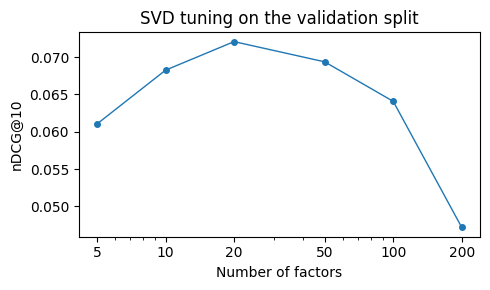

In [3]:
plot_svd_tuning(numbers_of_factors, validation_ndcg)

## Top-10 recommendations
Each user gets the 10 items with the highest score among the items they have not rated. A test rating >= 3 counts as relevant.

In [4]:
recommendations_per_model = {
    "TopPop": recommend_most_popular(train_df, test_df["user_id"].unique(), 10),
    "KNN": recommend_with_item_knn(train_df, 10),
    "SVD": recommend_with_svd(train_df, best_number_of_factors, 10),
}

compare_models(recommendations_per_model, test_df)

,HR,P@10,MAP@10,MRR@10,nDCG@10,Coverage
TopPop,0.230,0.026,0.021,0.077,0.047,0.020
KNN,0.461,0.062,0.064,0.202,0.123,0.704
SVD,0.407,0.053,0.052,0.173,0.103,0.310


## Long tail analysis
Hit rate for the 20% most and least active users. For the 20% most and least rated items: the share of those items that are recommended to at least one user.

In [5]:
most_active_users, least_active_users = split_most_and_least_active(train_df, "user_id")
most_rated_items, least_rated_items = split_most_and_least_active(train_df, "item_id")

long_tail_scores = {}
for model_name, recommendations in recommendations_per_model.items():
    scores = {}
    for group_name, user_ids in [("HitRate top users 20%", most_active_users), ("HitRate bottom users 20%", least_active_users)]:
        group_recommendations = {user_id: items for user_id, items in recommendations.items() if user_id in user_ids}
        group_test_df = test_df[test_df["user_id"].isin(user_ids)]
        scores[group_name] = hit_rate(group_recommendations, group_test_df)

    recommended_items = {item_id for user_items in recommendations.values() for item_id, _score in user_items}
    for group_name, item_ids in [("Coverage top items 20%", most_rated_items), ("Coverage bottom items 20%", least_rated_items)]:
        scores[group_name] = len(recommended_items & set(item_ids)) / len(item_ids)

    long_tail_scores[model_name] = scores

long_tail_table = pd.DataFrame(long_tail_scores).T.round(3)
long_tail_table

,HitRate top users 20%,HitRate bottom users 20%,Coverage top items 20%,Coverage bottom items 20%
TopPop,0.368,0.195,0.102,0.000
KNN,0.599,0.343,0.968,0.473
SVD,0.567,0.303,0.941,0.022


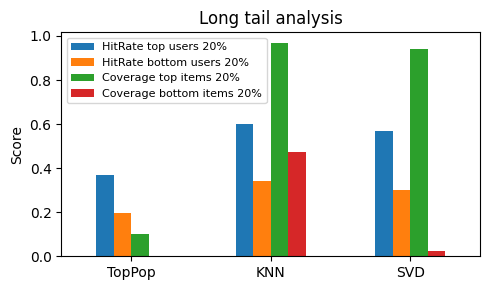

In [6]:
long_tail_table.plot(kind="bar", figsize=(5, 3), rot=0, title="Long tail analysis")
plt.ylabel("Score")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## A user with high and a user with low reciprocal rank (KNN)
The tables show the 10 recommended items and the rating the user gave them in the test set. NaN means the user did not rate the item in the test set, so it does not count as relevant.

In [7]:
knn_recommendations = recommendations_per_model["KNN"]
reciprocal_ranks = pd.Series(reciprocal_rank_per_user(knn_recommendations, test_df)).sort_values(ascending=False)

high_reciprocal_rank_user = reciprocal_ranks.index[0]
low_reciprocal_rank_user = reciprocal_ranks[reciprocal_ranks > 0].index[-1]

for user_id in [high_reciprocal_rank_user, low_reciprocal_rank_user]:
    user_train_ratings = train_df[train_df["user_id"] == user_id]["rating"]
    user_test_ratings = test_df[test_df["user_id"] == user_id].set_index("item_id")["rating"]

    recommended_items = pd.DataFrame(knn_recommendations[user_id], columns=["item_id", "score"])
    recommended_items["test_rating"] = recommended_items["item_id"].map(user_test_ratings)

    print(f"user {user_id}: RR={reciprocal_ranks[user_id]:.3f}, "
          f"{len(user_train_ratings)} training ratings with mean {user_train_ratings.mean():.2f}")
    display(recommended_items.round(2))

user AH6STWSNDF6MG4EY4SG3RHF7QVGA: RR=1.000, 21 training ratings with mean 4.43


,item_id,score,test_rating
0,B00NOD0OTW,1.60,5.0
1,B00BN5T30E,1.56,NaN
2,B014R4KYMS,1.54,NaN
3,B006YDPU48,1.36,5.0
4,B00DV16N6U,1.34,NaN
5,B00LV8HZH6,1.34,NaN
6,B007CM0K86,1.34,NaN
7,B00KIWEMIG,1.27,NaN
8,B00KIFM28A,1.27,NaN
9,B0083GAF9E,1.26,NaN


user AFPPQWRXBMVYSKEOBFWLEIODDZZQ: RR=0.100, 20 training ratings with mean 4.90


,item_id,score,test_rating
0,B001E8WQKY,1.46,NaN
1,B001EYUPHO,1.35,NaN
2,B000B69E9G,1.32,NaN
3,B0086VPUHI,1.31,NaN
4,B001D8Q5MA,1.28,NaN
5,B001EYUQVE,1.28,NaN
6,B001EYUXXK,1.27,NaN
7,B001EYUQTQ,1.26,NaN
8,B004D4YDPC,1.23,NaN
9,B002I0H79C,1.19,5.0
